In [3]:
# helper packages
import numpy as np
import xarray as xr
from scipy.constants import speed_of_light as c
import matplotlib.pyplot as plt

import pandas as pd

plt.style.use('figsettings.mplstyle')

from pycontrails import Flight, MetDataset
from pycontrails.datalib.ecmwf import ERA5
from pycontrails.models.cocip import Cocip
from pycontrails.models.humidity_scaling import ConstantHumidityScaling
from pycontrails.models.cocipgrid import CocipGrid
from pycontrails.models.humidity_scaling import HistogramMatching
from pycontrails.models.ps_model import PSGrid
from pycontrails.models.issr import ISSR
from pycontrails import MetDataArray, MetDataset, MetVariable

import cartopy.crs as ccrs

import matplotlib as mpl
import matplotlib.dates as mdates


### Fig. 5
The flight paths and ISSRs that drive contrail formation for Section 4.

In [5]:
df = pd.read_csv("aux_data/fleet_sample.csv")
df.altitude *= 0.3048 # convert to meters
df = df.set_index(['flight_id'])
fl = Flight(data=df, flight_id="csv")
fl["time"] = fl["time"] - np.timedelta64(1330, "D")

ids = df.index.unique()

flights = []
for idx, fl_id in enumerate(ids):
    flight_df = df.loc[fl_id]
    flight_attrs = {
        "nvpm_ei_n" : 1.897462e15,
        "wingspan": 48,  # m
        "n_engine": 2,
    }

    fl = Flight(data=flight_df, flight_id = fl_id, attrs = flight_attrs)
    fl["time"] = fl["time"] - np.timedelta64(1330, "D")
    fl["engine_efficiency"] = np.linspace(0.34, 0.35, fl.shape[0])
    fl["fuel_flow"] = np.linspace(2.1, 2.4, fl.shape[0])  # kg/s
    fl["aircraft_mass"] = np.linspace(154445, 154345, fl.shape[0])  # kg

    flights.append(fl)

    for i in np.arange(3):
        fl = Flight(data=flight_df, flight_id = fl_id, attrs = flight_attrs)
        fl.attrs["flight_id"] += str(i)
        fl["time"] = fl["time"] - np.timedelta64(6*(i + 1), "h") - np.timedelta64(1330, "D")
        fl["engine_efficiency"] = np.linspace(0.34, 0.35, fl.shape[0])
        fl["fuel_flow"] = np.linspace(2.1, 2.4, fl.shape[0])  # kg/s
        fl["aircraft_mass"] = np.linspace(154445, 154345, fl.shape[0])  # kg

        flights.append(fl)


/home/pczarnec/virtual_envs/cocip/lib/python3.12/site-packages/pycontrails/core/flight.py:263: UserWarning: Sorting Flight data by time.
  warnings.warn("Sorting Flight data by time.")
/home/pczarnec/virtual_envs/cocip/lib/python3.12/site-packages/pycontrails/core/flight.py:278: UserWarning: Flight contains 183814 duplicate times. This will cause errors with segment-based methods. Set 'drop_duplicated_times=True' or call the 'resample_and_fill' method.
  warnings.warn(
/home/pczarnec/virtual_envs/cocip/lib/python3.12/site-packages/pycontrails/core/vector.py:124: UserWarning: Overwriting data in key `time`. Use `.update(time=...)` to suppress warning.
  warnings.warn(
/home/pczarnec/virtual_envs/cocip/lib/python3.12/site-packages/pycontrails/core/vector.py:124: UserWarning: Overwriting data in key `time`. Use `.update(time=...)` to suppress warning.
  warnings.warn(
/home/pczarnec/virtual_envs/cocip/lib/python3.12/site-packages/pycontrails/core/vector.py:51: UserWarning: Overwriting att

In [6]:
time_bounds = ("2019-06-21 00:03:00", "2019-06-22 00:03:00") # summer solstice 2019

#pressure_levels = ["1", "10", "100", "125", "150", "175", "200", "225", "250", "300", "350", "400", "450", "500", "550", "600",
#        "650", "700", "750", "775", "800", "825", "850", "875", "900", "925", "950", "975", "1000"]
pressure_levels = [300, 250, 200]
era5pl = ERA5(
    time=time_bounds,
    variables= Cocip.met_variables + Cocip.optional_met_variables,
    pressure_levels=pressure_levels,
)

era5sl = ERA5(time=time_bounds, variables=Cocip.rad_variables)

met = era5pl.open_metdataset()
rad = era5sl.open_metdataset()

ds_cs = xr.open_dataset("aux_data/ERA5_solstice_cs_cdt.grib")

valid_times = ds_cs["valid_time"].values.flatten()

# CDS delivers these as 'tsrc' and 'ttrc' short names
# Rename them to 'tsr' and 'ttr' so CoCiP's rad_variables are satisfied
ds_cs = (
    ds_cs
    .stack(valid_time_flat=("time", "step"))  # use a temp name to avoid collision
    .assign_coords(valid_time_flat=valid_times.astype("datetime64[ns]"))
    .drop_vars(["number", "surface", "step"], errors="ignore")
    .rename({"valid_time_flat": "time", "tsrc": "top_net_solar_radiation", "ttrc": "top_net_thermal_radiation"})
    .assign_coords(longitude=((ds_cs["longitude"] + 180) % 360 - 180))
    .sortby(["time", "longitude"])
)

# Add a dummy pressure level dimension if not present (pycontrails MetDataset expects it)
if "level" not in ds_cs.dims:
    ds_cs = ds_cs.expand_dims({"level": [-1]})

rad = MetDataset(ds_cs, attrs = met.attrs)

# Zero out ciwc (and clwc if present) in the met dataset
met.data["specific_cloud_ice_water_content"] = xr.zeros_like(
    met.data["specific_cloud_ice_water_content"]
)

met.data["fraction_of_cloud_cover"] = xr.zeros_like(
    met.data["fraction_of_cloud_cover"]
)

if "specific_cloud_liquid_water_content" in met.data:
    met.data["specific_cloud_liquid_water_content"] = xr.zeros_like(
        met.data["specific_cloud_liquid_water_content"]
    )



sh: 1: getfattr: not found
sh: 1: getfattr: not found
sh: 1: getfattr: not found
sh: 1: getfattr: not found
sh: 1: getfattr: not found
sh: 1: getfattr: not found
sh: 1: getfattr: not found
sh: 1: getfattr: not found
sh: 1: getfattr: not found
sh: 1: getfattr: not found
sh: 1: getfattr: not found
sh: 1: getfattr: not found
sh: 1: getfattr: not found
sh: 1: getfattr: not found
sh: 1: getfattr: not found
sh: 1: getfattr: not found
sh: 1: getfattr: not found
sh: 1: getfattr: not found
sh: 1: getfattr: not found
sh: 1: getfattr: not found
sh: 1: getfattr: not found
sh: 1: getfattr: not found
sh: 1: getfattr: not found
sh: 1: getfattr: not found
sh: 1: getfattr: not found
sh: 1: getfattr: not found
sh: 1: getfattr: not found
sh: 1: getfattr: not found
sh: 1: getfattr: not found
sh: 1: getfattr: not found
sh: 1: getfattr: not found
sh: 1: getfattr: not found
sh: 1: getfattr: not found
sh: 1: getfattr: not found
sh: 1: getfattr: not found
sh: 1: getfattr: not found
sh: 1: getfattr: not found
s

In [7]:
issr_mds = ISSR(met).eval()
issr = issr_mds["issr"]
da = issr.data

/home/pczarnec/virtual_envs/cocip/lib/python3.12/site-packages/pycontrails/core/models.py:227: UserWarning: 
Met data appears to have originated from ECMWF and no humidity scaling is enabled. For ECMWF data, consider using one of: 
 - 'ConstantHumidityScaling'
 - 'ExponentialBoostHumidityScaling'
 - 'ExponentialBoostLatitudeCorrectionHumidityScaling'
 - 'HistogramMatching'
For example: 
>>> from pycontrails.models.humidity_scaling import ConstantHumidityScaling
>>> ISSR(met=met, ..., humidity_scaling=ConstantHumidityScaling(rhi_adj=0.99))
  warnings.warn(


In [8]:
t_start = np.datetime64('2019-06-21T03:00:00')  # 00:00 CDT
t_end   = np.datetime64('2019-06-22T03:00:00')  # 21:00 CDT

flights_filtered = [
    fl for fl in flights
    if fl["time"][-1] > t_start and fl["time"][0] < t_end
]

/tmp/ipykernel_2486614/160524440.py:69: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.savefig('figures/cocip_out.png', dpi = 300, bbox_inches = 'tight')
/tmp/ipykernel_2486614/160524440.py:69: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.savefig('figures/cocip_out.png', dpi = 300, bbox_inches = 'tight')
/net/nfs/tools/u20/Python/miniforge_25.11.0-1/envs/pangeo-meso-2026.01.21/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


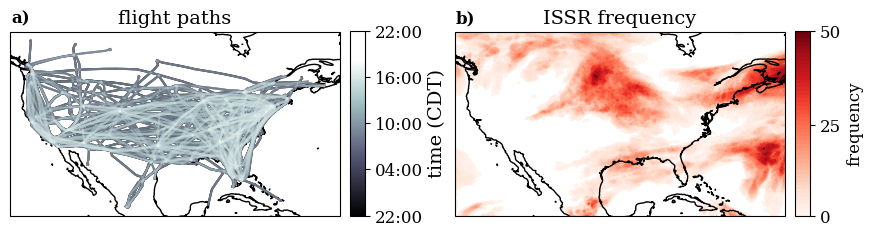

In [9]:
import matplotlib as mpl

fig = plt.figure(figsize=(10, 5), tight_layout = True)
gs = fig.add_gridspec(1, 2, height_ratios=[1], width_ratios=[1, 1], wspace = 0.35)
ax1 = fig.add_subplot(gs[0], projection=ccrs.PlateCarree())
ax2 = fig.add_subplot(gs[1], projection=ccrs.PlateCarree())

# Get start time for each flight
utc_to_cdt = np.timedelta64(5, 'h')
start_times_cdt = np.array([fl["time"][0] - utc_to_cdt for fl in flights_filtered])

# Convert to matplotlib's internal date-number format for normalization
start_nums = mdates.date2num(start_times_cdt)

window_start_cdt = np.datetime64('2019-06-20T22:00:00')
window_end_cdt   = np.datetime64('2019-06-21T22:00:00')

window_start_num = mdates.date2num(window_start_cdt)
window_end_num   = mdates.date2num(window_end_cdt)

colors = mpl.colormaps['bone']
norm = mpl.colors.Normalize(vmin = window_start_num, vmax = start_nums.max())
sm = mpl.cm.ScalarMappable(cmap = colors, norm = norm)
sm.set_array([])

min_alpha = 0.1

for idx, fl in enumerate(sorted(flights_filtered, key=lambda fl: fl["time"][0])):
    t_cdt = fl["time"][0] - utc_to_cdt
    t_clamped = min(max(t_cdt, window_start_cdt), window_end_cdt)
    t_num = mdates.date2num(t_clamped)
    
    frac = norm(t_num)  # 0 at window start, 1 at window end
    alpha = 1 - frac * (1 - min_alpha)  # scales from 1 down to min_alpha, not 0
    fl.plot(ax=ax1, color = colors(norm(t_num)), alpha=alpha)

ax1.yaxis.set_visible(False)
ax1.coastlines()
ax1.set_title("flight paths")

ax2.coastlines()
ax2.set_title("ISSR frequency")
lon_min, lon_max, lat_min, lat_max = ax1.get_extent(crs=ccrs.PlateCarree())
da_freq = da.sum(dim=['level', 'time']).sel(latitude=slice(lat_min, lat_max), longitude = slice(lon_min, lon_max)).compute()
sc = ax2.contourf(da_freq.longitude, da_freq.latitude, da_freq.T, cmap = "Reds", vmin = 1, levels = np.arange(1, 51))

cax = fig.add_axes([0.91, 0.312, 0.015, 0.37])
cbar = fig.colorbar(sc, cax=cax, ticks = [1, 25, 50])
cbar.ax.set_yticklabels([0, 25, 50])
cbar.set_label('frequency', fontsize = 12)

cax = fig.add_axes([0.465, 0.312, 0.015, 0.37])
cbar = fig.colorbar(sm, cax = cax,)

tick_times = np.array([
    np.datetime64('2019-06-20T22:00:00'),  # first
    np.datetime64('2019-06-21T04:00:00'),
    np.datetime64('2019-06-21T10:00:00'),
    np.datetime64('2019-06-21T16:00:00'),
    np.datetime64('2019-06-21T22:00:00'),  # last
])
cbar.set_ticks(mdates.date2num(tick_times))
cbar.ax.set_yticklabels([np.datetime_as_string(t, unit='m')[-5:] for t in tick_times])
cbar.set_label('time (CDT)')

ax1.text(0.06, 1.03, 'a)', transform=ax1.transAxes, ha='right', va='bottom', fontsize = 12, fontweight='bold')
ax2.text(0.06, 1.03, 'b)', transform=ax2.transAxes, ha='right', va='bottom', fontsize = 12, fontweight='bold')

plt.savefig('figures/cocip_out.png', dpi = 300, bbox_inches = 'tight')
plt.show()